<a href="https://colab.research.google.com/github/192412566/mechine-learning-lab/blob/main/Harini_Mech_Learn_Exp_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset created successfully!
Number of samples: 100
Iteration: 1 | Means: [1.857 7.055] | Weights: [0.507 0.493]
Iteration: 11 | Means: [1.844 7.043] | Weights: [0.505 0.495]
Iteration: 21 | Means: [1.844 7.043] | Weights: [0.505 0.495]
Iteration: 31 | Means: [1.844 7.043] | Weights: [0.505 0.495]
Iteration: 41 | Means: [1.844 7.043] | Weights: [0.505 0.495]

FINAL EM PARAMETERS

Cluster 1
Mean: 1.8442
Variance: 0.604
Weight: 0.5048

Cluster 2
Mean: 7.0434
Variance: 0.6886
Weight: 0.4952

CLUSTER ASSIGNMENTS
Data: 2.397 -> Cluster: 1
Data: 1.889 -> Cluster: 1
Data: 2.518 -> Cluster: 1
Data: 3.218 -> Cluster: 1
Data: 1.813 -> Cluster: 1
Data: 1.813 -> Cluster: 1
Data: 3.263 -> Cluster: 1
Data: 2.614 -> Cluster: 1
Data: 1.624 -> Cluster: 1
Data: 2.434 -> Cluster: 1
Data: 1.629 -> Cluster: 1
Data: 1.627 -> Cluster: 1
Data: 2.194 -> Cluster: 1
Data: 0.469 -> Cluster: 1
Data: 0.62 -> Cluster: 1
Data: 1.55 -> Cluster: 1
Data: 1.19 -> Cluster: 1
Data: 2.251 -> Cluster: 1
Data: 1.274 -> Clust

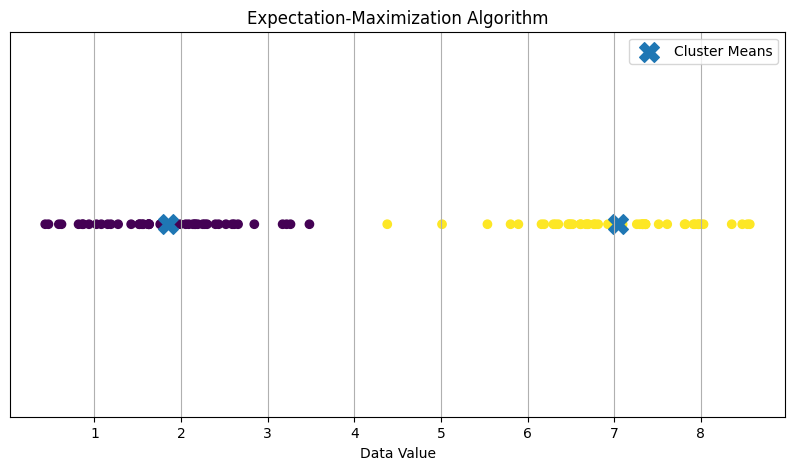

In [1]:
# ============================================================
# EXPECTATION-MAXIMIZATION (EM) ALGORITHM
# Gaussian Mixture Model
# Google Colab - No CSV Required
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Create Dataset
# ------------------------------------------------------------

np.random.seed(42)

# Generate two groups of data
data1 = np.random.normal(
    loc=2,
    scale=0.8,
    size=50
)

data2 = np.random.normal(
    loc=7,
    scale=1.0,
    size=50
)

X = np.concatenate([
    data1,
    data2
])

X = X.reshape(-1, 1)

print("Dataset created successfully!")
print("Number of samples:", len(X))


# ------------------------------------------------------------
# 2. Initialize Parameters
# ------------------------------------------------------------

# Number of Gaussian components
K = 2

# Initial means
means = np.array([
    [2.0],
    [7.0]
])

# Initial variances
variances = np.array([
    [1.0],
    [1.0]
])

# Initial mixing coefficients
weights = np.array([
    0.5,
    0.5
])


# ------------------------------------------------------------
# 3. Gaussian Probability Density Function
# ------------------------------------------------------------

def gaussian_pdf(x, mean, variance):

    return (
        1 / np.sqrt(2 * np.pi * variance)
    ) * np.exp(
        -((x - mean) ** 2) /
        (2 * variance)
    )


# ------------------------------------------------------------
# 4. EM Algorithm
# ------------------------------------------------------------

iterations = 50

for iteration in range(iterations):

    # ========================================================
    # EXPECTATION STEP
    # ========================================================

    responsibilities = np.zeros(
        (len(X), K)
    )

    for k in range(K):

        responsibilities[:, k] = (
            weights[k] *
            gaussian_pdf(
                X[:, 0],
                means[k, 0],
                variances[k, 0]
            )
        )

    # Normalize responsibilities
    responsibilities = (
        responsibilities /
        responsibilities.sum(
            axis=1,
            keepdims=True
        )
    )


    # ========================================================
    # MAXIMIZATION STEP
    # ========================================================

    N_k = responsibilities.sum(
        axis=0
    )

    # Update means
    for k in range(K):

        means[k, 0] = (
            np.sum(
                responsibilities[:, k] *
                X[:, 0]
            )
            / N_k[k]
        )

    # Update variances
    for k in range(K):

        variances[k, 0] = (
            np.sum(
                responsibilities[:, k] *
                (X[:, 0] - means[k, 0]) ** 2
            )
            / N_k[k]
        )

    # Update weights
    weights = N_k / len(X)


    # --------------------------------------------------------
    # Display progress
    # --------------------------------------------------------

    if iteration % 10 == 0:

        print(
            "Iteration:",
            iteration + 1,
            "| Means:",
            np.round(means.flatten(), 3),
            "| Weights:",
            np.round(weights, 3)
        )


# ------------------------------------------------------------
# 5. Display Final Parameters
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL EM PARAMETERS")
print("=" * 60)

for k in range(K):

    print(
        "\nCluster",
        k + 1
    )

    print(
        "Mean:",
        round(float(means[k, 0]), 4)
    )

    print(
        "Variance:",
        round(float(variances[k, 0]), 4)
    )

    print(
        "Weight:",
        round(float(weights[k]), 4)
    )


# ------------------------------------------------------------
# 6. Assign Each Sample to a Cluster
# ------------------------------------------------------------

cluster_labels = np.argmax(
    responsibilities,
    axis=1
)

print("\n" + "=" * 60)
print("CLUSTER ASSIGNMENTS")
print("=" * 60)

for i in range(len(X)):

    print(
        "Data:",
        round(float(X[i, 0]), 3),
        "-> Cluster:",
        cluster_labels[i] + 1
    )


# ------------------------------------------------------------
# 7. Visualize Clusters
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.scatter(
    X[:, 0],
    np.zeros(len(X)),
    c=cluster_labels
)

plt.scatter(
    means[:, 0],
    np.zeros(K),
    marker='X',
    s=200,
    label='Cluster Means'
)

plt.xlabel("Data Value")
plt.yticks([])

plt.title(
    "Expectation-Maximization Algorithm"
)

plt.legend()

plt.grid(True)

plt.show()